# **Minor Project-2**

## **Title: Customer Behavior Analysis & Business Decision Making**

### **SECTION 1: Data Understanding**

In [ ]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv("Mall_Customers.csv")

# 2. Display the dataset
print(df)
print("\n")

# 3. Display the shape and columns
print("Shape of the dataset:", df.shape)
print("\nColumns:", df.columns.tolist())

# 4. Check missing values and data types
print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]


Shape of the dataset: (200, 5)

Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Sp

**Questions:**

**1. What type of dataset is this?**

   The Mall Customer Segmentation dataset is a structured, tabular dataset containing customer information, including age, gender, annual income, and spending score.

**2. Which features are numerical/categorical?**

  * Numerical: Age, Annual Income (k$), Spending Score (1-100).

  * Categorical: Gender.

  * Identifier: CustomerID, which uniquely identifies each customer and is excluded from meaningful numerical analysis.

### **SECTION 2: Descriptive Analysis**

In [ ]:
# Calculate mean, median, and standard deviation
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

print("Descriptive Analysis:\n")
print(df[features].agg(["mean", "median", "std"]).round(2))

Descriptive Analysis:

          Age  Annual Income (k$)  Spending Score (1-100)
mean    38.85               60.56                   50.20
median  36.00               61.50                   50.00
std     13.97               26.26                   25.82


**Questions:**

**1. Which feature shows highest variability?**

   Annual Income shows the highest variability, with a standard deviation of 26.26. Spending Score has a standard deviation of 25.82, while Age has a standard deviation of 13.97. Therefore, Annual Income has the highest variability among the three features.

**2.Are customers similar or diverse?**

  Customers are diverse because their ages, annual incomes, and spending scores vary. The standard deviations indicate differences in these features, particularly in annual income and spending score. This suggests that customers have different age groups, income levels, and spending behaviors.



### **SECTION 3: Visualization**

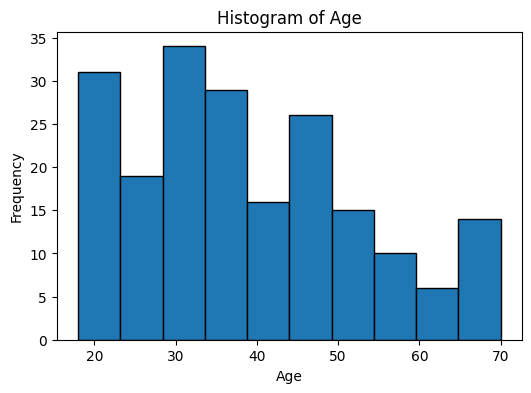

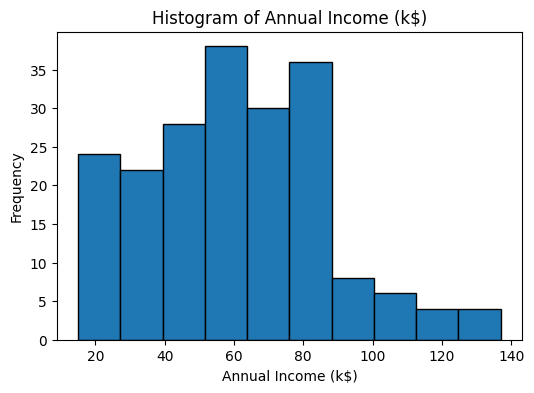

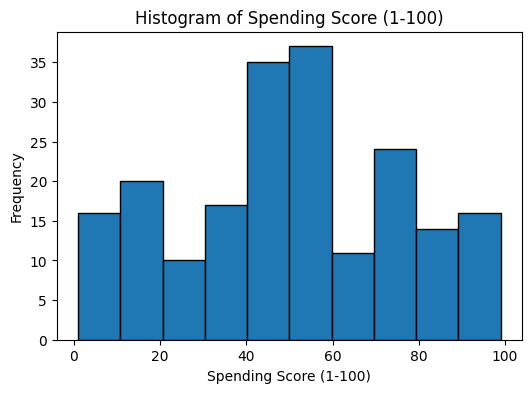

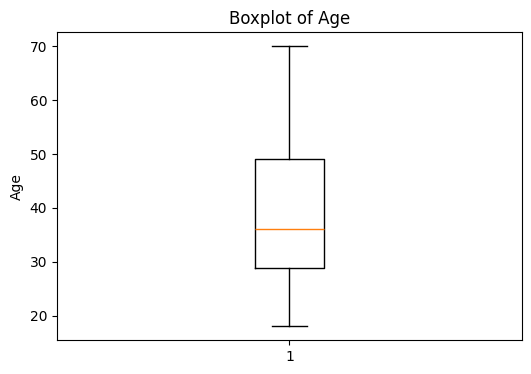

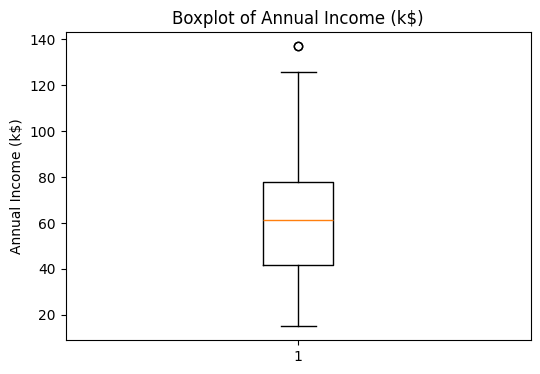

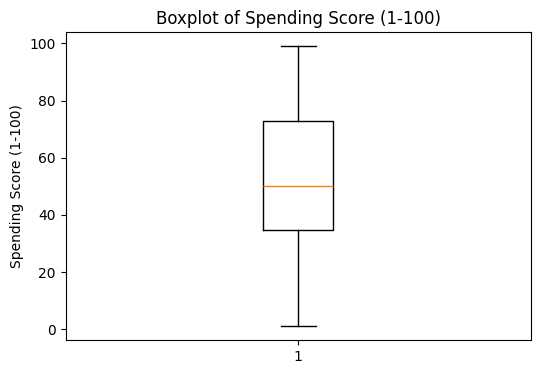

In [ ]:
# compute histograms and boxplot
import matplotlib.pyplot as plt

# Select the features for visualization
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

# 1. Plot histograms
for feature in features:
    plt.figure(figsize=(6, 4))
    plt.hist(df[feature], bins=10, edgecolor="black")
    plt.title(f"Histogram of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.show()

# 2. Plot boxplots to detect outliers
for feature in features:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[feature])
    plt.title(f"Boxplot of {feature}")
    plt.ylabel(feature)
    plt.show()

**Questions:**

**1. Is the data skewed?**

 - Age: The distribution is slightly positively skewed.

- Annual Income: The distribution is positively (right) skewed.

- Spending Score: The distribution is not perfectly symmetrical.

  Conclusion: Annual Income shows the clearest positive skew.

**2. Are there extreme customers?**

  - Age: No outliers are visible.

  - Annual Income: One potential high-income outlier is visible at approximately $137,000.
  
  - Spending Score: No outliers are visible.

   Conclusion: One potential extreme customer is identified in the Annual Income boxplot.



### **SECTION 4: Group-Based Analysis**

In [ ]:
# Compare Male vs Female customers

# Calculate average spending score and annual income by gender
result = df.groupby("Gender").agg({
    "Spending Score (1-100)": "mean",
    "Annual Income (k$)": "mean"
})

print("Average Spending Score and Annual Income by Gender:")
print("\n")
print(result.round(2))


Average Spending Score and Annual Income by Gender:
        Spending Score (1-100)  Annual Income (k$)
Gender                                            
Female                   51.53               59.25
Male                     48.51               62.23


**Questions:**

**1. Which group spends more?**

  Female customers spend more on average, with a Spending Score of 51.53, compared to 48.51 for male customers.

**2. Is there a visible difference?**

  Yes, there is a small difference between male and female customers. Female customers have a slightly higher average Spending Score, whereas male customers have a slightly higher average Annual Income. This indicates a small difference in spending scores and income between the two groups.



### **SECTION 5: Correlation Analysis**

Correlation between Income and Spending Score: 0.01
Correlation between Age and Spending Score: -0.327


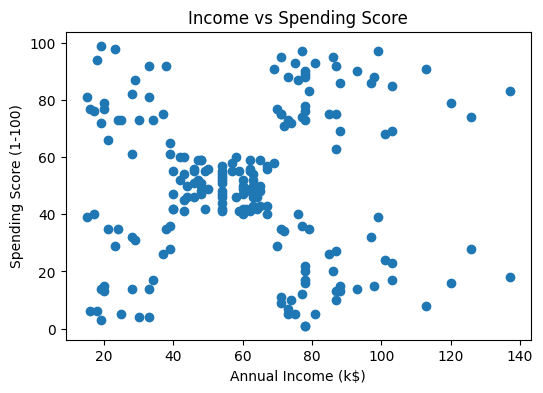

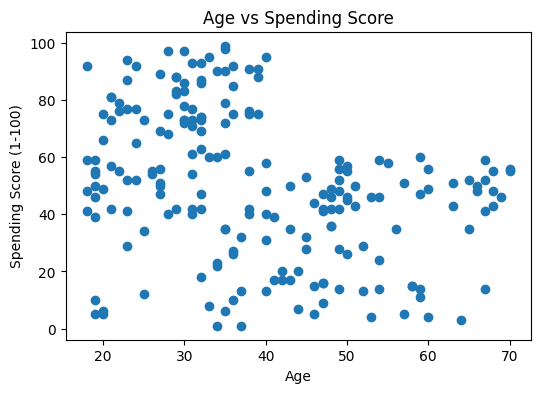

In [ ]:
# Calculate correlations
income_corr = df["Annual Income (k$)"].corr(df["Spending Score (1-100)"])
age_corr = df["Age"].corr(df["Spending Score (1-100)"])

print("Correlation between Income and Spending Score:", round(income_corr, 3))
print("Correlation between Age and Spending Score:", round(age_corr, 3))

# Plot Income vs Spending Score
plt.figure(figsize=(6, 4))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"])
plt.title("Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()
print("\n")

# Plot Age vs Spending Score
plt.figure(figsize=(6, 4))
plt.scatter(df["Age"], df["Spending Score (1-100)"])
plt.title("Age vs Spending Score")
plt.xlabel("Age")
plt.ylabel("Spending Score (1-100)")
plt.show()

**Questions:**

**1. Do richer customers spend more?**

  The correlation between Annual Income and Spending Score is 0.01, indicating almost no linear relationship. Therefore, higher-income customers do not necessarily have higher spending scores.

**2. Does age affect spending?**

   The correlation between Age and Spending Score is -0.327, indicating a weak negative relationship. This suggests that spending scores tend to decrease as age increases.

### **SECTION 6: Inferential Statistics (CORE)**



In [ ]:
#Do male and female customers spend differently
from scipy import stats

# Separate spending scores by gender
male = df[df["Gender"] == "Male"]["Spending Score (1-100)"]
female = df[df["Gender"] == "Female"]["Spending Score (1-100)"]

# Perform independent samples t-test
t_stat, p_value = stats.ttest_ind(male, female)

print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

# Make a decision at the 5% significance level
if p_value < 0.05:
    print("Reject H0: There is a statistically significant difference.")
else:
    print("Fail to reject H0: There is no statistically significant difference.")

T-statistic: -0.819
P-value: 0.4137
Fail to reject H0: There is no statistically significant difference.


**Questions:**

**1. What does p-value tell you?**

  The p-value is 0.4137, which is greater than 0.05, indicating insufficient evidence of a difference in average Spending Scores between male and female customers.

**2. Is the difference statistically significant?**

   No, the difference is not statistically significant because the p-value (0.4137) is greater than 0.05. Therefore, we fail to reject the null hypothesis (H₀).

### **SECTION 7: Confidence Interval**

In [ ]:
#Calculate 95% CI for the Spending Score.

# Select Spending Score
spending = df["Spending Score (1-100)"]

# Calculate the sample mean and standard error
mean = spending.mean()
standard_error = stats.sem(spending)

# Calculate the 95% confidence interval
ci = stats.t.interval(
    confidence=0.95,
    df=len(spending) - 1,
    loc=mean,
    scale=standard_error
)

print("Mean Spending Score:", round(mean, 2))
print("95% Confidence Interval:", (round(ci[0], 2), round(ci[1], 2)))

Mean Spending Score: 50.2
95% Confidence Interval: (np.float64(46.6), np.float64(53.8))


**Questions:**

**1. What range do customers fall into?**

  The 95% confidence interval is 46.60 to 53.80, with a mean Spending Score of 50.20. This means the estimated population average Spending Score lies between 46.60 and 53.80.

**2. How confident are we?**

  We are 95% confident that the calculated interval contains the true population average Spending Score.

### **SECTION 8: Business Insights**

**1. Which customers should the business target?**

  The business should target customers with high Spending Scores, as they are more likely to spend more at the mall. It can also target younger customers, because the analysis shows a weak negative relationship between age and spending score.

**2. Does income affect spending?**

  No strong relationship was found between annual income and spending score. The correlation coefficient is 0.01, which indicates almost no linear relationship. Therefore, customers with higher incomes do not necessarily spend more.


**3. Should marketing differ by gender?**

  Female customers have a slightly higher average spending score than males, but the difference is not statistically significant. Therefore, marketing should not depend on gender alone.

**4. What strategy would you suggest?**

  The business should use customer spending patterns to design targeted marketing campaigns. It can offer loyalty rewards to high-spending customers, personalized offers based on customer preferences, and special promotions to encourage more purchases. Since income has almost no relationship with spending score, marketing should focus more on customers spending behaviour than their income.

